## 1. What will the hub need next week?

The sales analysis gives us a daily requirement history for each stock item. We now use those histories to estimate the next seven days for the central hub, with all three shops combined. These quantities are based on recorded sales and the defined recipes.

In [1]:

from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from html import escape
ROOT = Path.cwd()
if not (ROOT / 'results/weekly').exists():
    ROOT = ROOT.parent
OUT = ROOT / 'results/weekly'
manifest = json.loads((OUT / 'experiment.json').read_text())
assert manifest['complete']
for name, digest in manifest['input_hashes'].items():
    assert hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == digest
for name, digest in manifest['output_hashes'].items():
    assert hashlib.sha256((OUT / name).read_bytes()).hexdigest() == digest
daily = pd.read_csv(OUT / 'hub_daily.csv', index_col=0, parse_dates=True)
groups = pd.read_csv(OUT / 'item_groups.csv')
selection = pd.read_csv(OUT / 'selection.csv')
scores = pd.read_csv(OUT / 'scores.csv')
forecasts = pd.read_csv(OUT / 'forecasts.csv', parse_dates=['date','origin'])
items = pd.read_csv(OUT / 'item_selection.csv')
representatives = groups.drop_duplicates('group_id').set_index('group_id')
def table(frame, css_class=""):
    frame = frame.copy()
    frame.columns = [str(c).replace('_', ' ') for c in frame.columns]
    display(HTML(frame.to_html(index=False, border=0, classes=css_class, float_format=lambda x: f'{x:,.3f}')))
def expandable(frame, label, preview=8, css_class=""):
    classes = "forecast-results " + css_class
    def markup(rows):
        return rows.to_html(index=False, border=0, classes=classes, float_format=lambda x: f'{x:,.3f}')
    head = markup(frame.head(preview))
    remaining = frame.iloc[preview:]
    if remaining.empty:
        display(HTML(head))
        return
    toggle = f'<summary><span class="expand-label">{escape(label)} · {len(remaining)} more / {len(frame)} total</span><span class="collapse-label">Show fewer rows</span><span class="disclosure-icon" aria-hidden="true"></span></summary>'
    display(HTML('<div class="result-table">'+head+'<details class="result-details result-expansion">'+toggle+markup(remaining)+'</details></div>'))

# A shared ingredient can belong to many menu products. Order it by the lowest
# linked product ID, with stock ID as a stable secondary key.
bom = pd.read_csv(ROOT / 'data/assumptions/bom.csv')
product_order = bom.groupby('material_id').product_id.min()
group_order = bom.merge(groups[['material_id','group_id']], on='material_id').groupby('group_id').product_id.min()
def order_groups(frame):
    frame = frame.copy()
    frame['_product_order'] = group_order.reindex(frame.index)
    frame['_stock_id'] = frame.index
    return frame.sort_values(['_product_order','_stock_id']).drop(columns=['_product_order','_stock_id'])

def note(text):
    display(HTML('<p>' + text + '</p>'))
plt.rcParams.update({'figure.figsize':(11,3.6), 'font.size':11, 'axes.spines.top':False,
                     'axes.spines.right':False, 'axes.titlelocation':'left'})
PURPLE, GRAY, TEAL = '#635bff', '#8993a4', '#00857d'
summary = groups.groupby('inventory_type').agg(Items=('material_id','size'), Forecast_groups=('group_id','nunique')).reset_index()
table(summary.rename(columns={'inventory_type':'Stock type','Forecast_groups':'Forecast groups'}))
note('The 64 stock items form 61 forecasting groups. Each Small, Regular and Large cup is paired with a matching lid in the BOM, so those three pairs share the same forecast. The remaining items are forecast individually.')


Stock type,Items,Forecast groups
Finished goods,39,39
Ingredient,18,18
Packaging,7,4


## 2. Recreate a weekly planning decision

To judge a forecast fairly, we must make it before the sales it predicts are known. We begin with January–April, predict a week in May, then move forward one week and repeat. May helps choose the method for each item; June checks those choices on later dates.

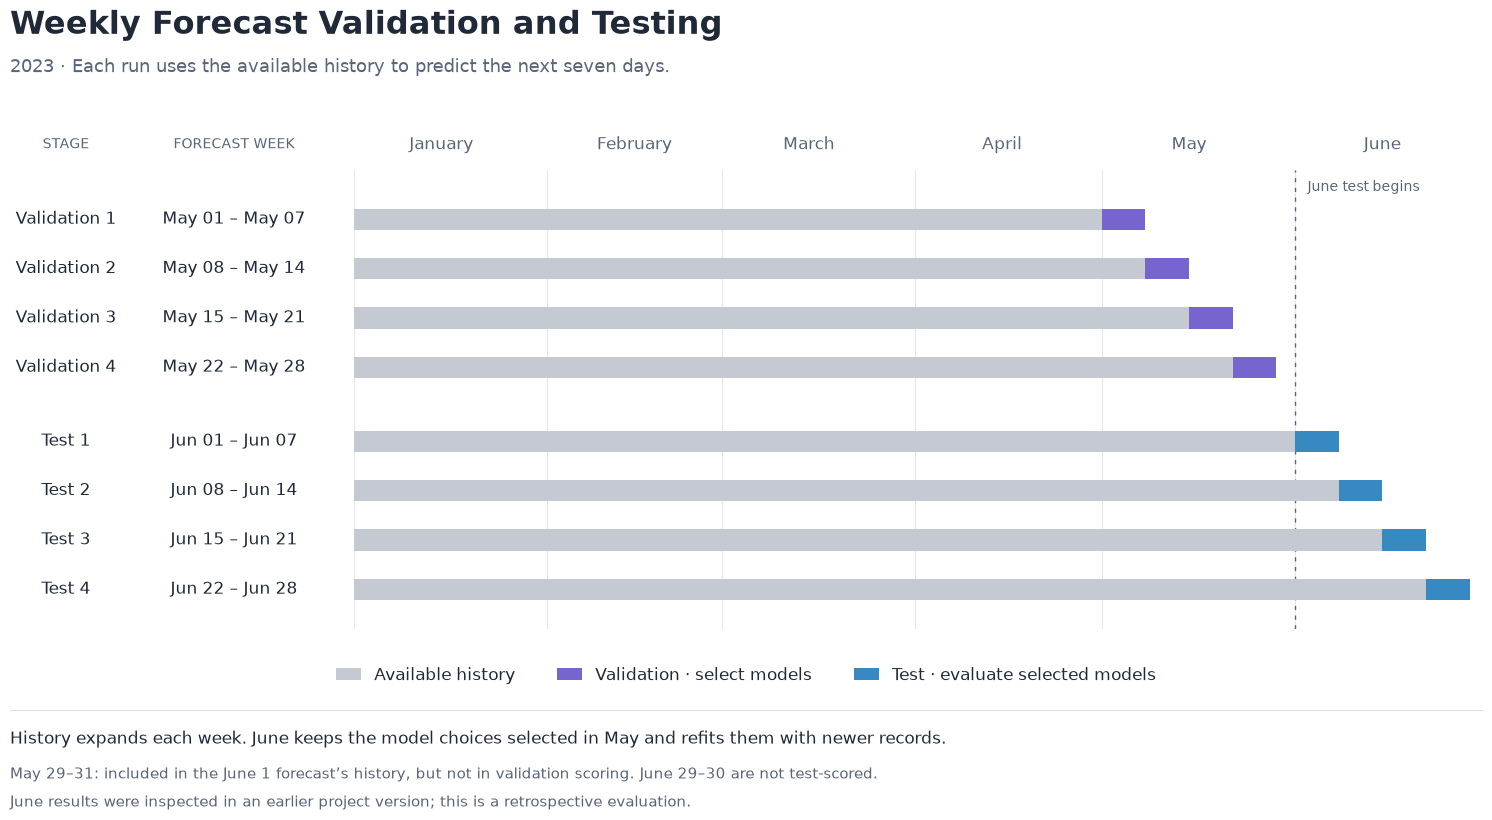

In [2]:

from datetime import datetime, timedelta
import matplotlib.dates as md
from matplotlib.patches import Patch

bg, fg, muted = '#ffffff', '#202938', '#596579'
history, validation, test = '#c4c9d2', '#7864ce', '#368ac1'
fig, ax = plt.subplots(figsize=(16, 8.5), facecolor=bg)
ax.set_facecolor(bg)
fig.subplots_adjust(left=.255, right=.96, top=.78, bottom=.24)
start = datetime(2023,1,1)
starts = [pd.Timestamp(origin).to_pydatetime() + timedelta(days=1)
          for key in ['validation_origins', 'test_origins'] for origin in manifest[key]]
assert len(starts) == 8
ys = [8,7,6,5,3.5,2.5,1.5,.5]
for i,(d,y) in enumerate(zip(starts,ys)):
    color = validation if i<4 else test
    ax.barh(y,(d-start).days,left=md.date2num(start),height=.43,color=history)
    ax.barh(y,7,left=md.date2num(d),height=.43,color=color)
    ax.text(-.1064,y,f'{d:%b %d} – {d+timedelta(days=6):%b %d}',transform=ax.get_yaxis_transform(),ha='center',va='center',color=fg,fontsize=12)
    stage = f'Validation {i+1}' if i < 4 else f'Test {i-3}'
    ax.text(-.2553,y,stage,transform=ax.get_yaxis_transform(),ha='center',va='center',color=fg,fontsize=12)
months = [datetime(2023,m,1) for m in range(1,7)]
for d in months:
    ax.axvline(md.date2num(d),color='#e5e7eb',lw=.8,zorder=0)
ax.axvline(md.date2num(datetime(2023,7,1)),color='#e5e7eb',lw=.8,zorder=0)
ax.axvline(md.date2num(datetime(2023,6,1)),color=muted,lw=1,ls=(0,(3,4)),zorder=0)
ax.set_xlim(start,datetime(2023,7,1))
ax.set_ylim(-.3,9)
ax.set_yticks([])
ax.set_xticks([md.date2num(d)+14 for d in months],['January','February','March','April','May','June'],color=muted,fontsize=12)
ax.xaxis.tick_top()
ax.tick_params(axis='both',length=0,pad=12)
for spine in ax.spines.values(): spine.set_visible(False)
ax.text(-.2553,1.055,'STAGE',transform=ax.transAxes,ha='center',va='center',color=muted,fontsize=10)
ax.text(-.1064,1.055,'FORECAST WEEK',transform=ax.transAxes,ha='center',va='center',color=muted,fontsize=10)
ax.text(md.date2num(datetime(2023,6,1))+2,8.65,'June test begins',color=muted,fontsize=10,va='center')
fig.text(.04,.94,'Weekly Forecast Validation and Testing',color=fg,fontsize=23,weight='bold')
fig.text(.04,.895,'2023 · Each run uses the available history to predict the next seven days.',color=muted,fontsize=13)
fig.legend(handles=[Patch(facecolor=history,label='Available history'),Patch(facecolor=validation,label='Validation · select models'),Patch(facecolor=test,label='Test · evaluate selected models')],loc='center',bbox_to_anchor=(.5,.185),ncol=3,frameon=False,labelcolor=fg,fontsize=12,handlelength=1.5,columnspacing=2.5)
fig.add_artist(plt.Line2D([.04,.96],[.145,.145],transform=fig.transFigure,color='#d9dde5',lw=.8))
fig.text(.04,.105,'History expands each week. June keeps the model choices selected in May and refits them with newer records.',color=fg,fontsize=12)
fig.text(.04,.064,'May 29–31: included in the June 1 forecast’s history, but not in validation scoring. June 29–30 are not test-scored.',color=muted,fontsize=10.5)
fig.text(.04,.031,'June results were inspected in an earlier project version; this is a retrospective evaluation.',color=muted,fontsize=10.5)
plt.show()



## 3. Try different ways of anticipating demand

We compare two families of forecasting methods using the same weekly validation and test periods. Both use the hub’s daily requirement history.

Here, seasonal means a seven-day pattern. Six months contain repeated weeks, but cannot establish a recurring annual pattern. Keeping seasonal models in the comparison lets us check whether weekly repetition actually helps.

In [3]:

display(HTML('<h3>Classical Statistical Models</h3>'))
note('We begin with simple baselines, then test methods that follow changes in level, trend and weekly patterns.')
table(pd.DataFrame([
['Naive / Seasonal naive','Repeat the latest day, or the same weekday from last week.'],
['Moving average','Use the average of the most recent 7 or 14 days.'],
['SES / Holt','Smooth recent values; Holt also follows a changing trend.'],
['Holt–Winters','Combine level and trend with a repeating weekly pattern.'],
['ARIMA / SARIMA','Use relationships with earlier observations; SARIMA adds a weekly component.'],
], columns=['Method','How it anticipates the next few days']))
display(HTML('<h3>Machine Learning Models</h3>'))
note('We start with a linear baseline, add regularization, then compare two tree ensembles for nonlinear patterns. All four methods use the same lag, rolling and calendar features and recursively predict seven days.')
table(pd.DataFrame([
['Linear regression','Establish a linear baseline using recent requirements and calendar features.'],
['Ridge regression','Learn a regularized linear relationship between the input features and the next day’s requirement.'],
['Random forest','Average 100 small trees to capture nonlinear relationships while limiting individual-tree complexity.'],
['Gradient boosting','Combine small decision trees to learn nonlinear relationships between the same features and the next day’s requirement.'],
], columns=['Method','How it anticipates the next few days']))



Method,How it anticipates the next few days
Naive / Seasonal naive,"Repeat the latest day, or the same weekday from last week."
Moving average,Use the average of the most recent 7 or 14 days.
SES / Holt,Smooth recent values; Holt also follows a changing trend.
Holt–Winters,Combine level and trend with a repeating weekly pattern.
ARIMA / SARIMA,Use relationships with earlier observations; SARIMA adds a weekly component.


Method,How it anticipates the next few days
Linear regression,Establish a linear baseline using recent requirements and calendar features.
Ridge regression,Learn a regularized linear relationship between the input features and the next day’s requirement.
Random forest,Average 100 small trees to capture nonlinear relationships while limiting individual-tree complexity.
Gradient boosting,Combine small decision trees to learn nonlinear relationships between the same features and the next day’s requirement.


## 4. Explore how the methods forecast

Choose a demand pattern and a method to compare seven-day forecasts using the same 84 days of synthetic demand. The chart shows the final 28 history days. This is a teaching example, not a ranking of the project’s models.

In [4]:

import sys
if str(ROOT/'src') not in sys.path: sys.path.insert(0,str(ROOT/'src'))
from forecast_method_demo import build_demo
display(HTML(build_demo()))



## 5. Measure forecast performance

Forecast errors can describe the size of a miss, its direction or its size relative to normal variation. Because the hub stocks items measured in litres, kilograms and individual units, each measure answers a different question.

In [5]:

assert all(selection.n == 28)
table(pd.DataFrame([
['MSE / RMSE','MSE averages squared errors; RMSE takes the square root. Both give larger misses more weight.','Useful when large misses deserve extra attention. RMSE keeps the item’s original unit, but neither measure represents actual shortage or waste costs.'],
['MAE','Average absolute difference between forecast and recorded requirement.','A milk MAE of 2 L means an average daily miss of 2 litres. Easy to interpret for one item, but not directly comparable across litres, kilograms and units.'],
['Bias','Average signed error, defined here as recorded requirement minus forecast.','Positive values indicate underforecasting; negative values indicate overforecasting. Useful for spotting direction, but positive and negative errors can cancel, so a value near zero does not guarantee accuracy.'],
['MASE','Average absolute error divided by a historical reference error.','Allows comparison across different units. A seven-day reference can reflect weekly patterns, but very small historical variation makes the score unstable; a zero reference makes it undefined.'],
], columns=['Measure','What it means','When it helps — and its limits']), css_class='metric-explanation')



Measure,What it means,When it helps — and its limits
MSE / RMSE,MSE averages squared errors; RMSE takes the square root. Both give larger misses more weight.,"Useful when large misses deserve extra attention. RMSE keeps the item’s original unit, but neither measure represents actual shortage or waste costs."
MAE,Average absolute difference between forecast and recorded requirement.,"A milk MAE of 2 L means an average daily miss of 2 litres. Easy to interpret for one item, but not directly comparable across litres, kilograms and units."
Bias,"Average signed error, defined here as recorded requirement minus forecast.","Positive values indicate underforecasting; negative values indicate overforecasting. Useful for spotting direction, but positive and negative errors can cancel, so a value near zero does not guarantee accuracy."
MASE,Average absolute error divided by a historical reference error.,"Allows comparison across different units. A seven-day reference can reflect weekly patterns, but very small historical variation makes the score unstable; a zero reference makes it undefined."


## 6. Choose one model for each group

Each of the 61 groups is evaluated separately. All eligible classical and ML candidates compete on the same 28 May dates. We use MSE to give larger daily misses more weight; this is an error-based rule, not an inventory-cost calculation.

Selection rule: choose the candidate with the lowest May MSE. Exact ties use alphabetical model name only for reproducibility. A candidate must produce all 28 validation forecasts. June results do not change the model choice.

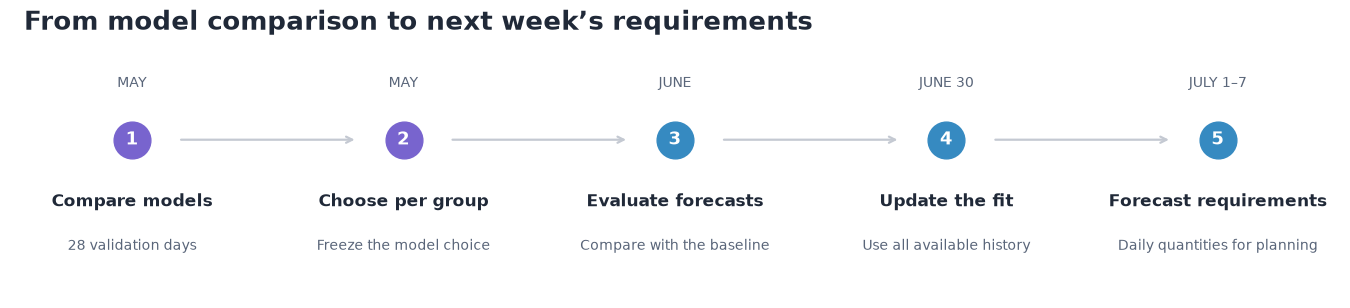

Group / stock items,Unit,Selected model,May MSE,Eligible candidates
Brazilian - Organic,each,Boosting(10),2.096,15
Our Old Time Diner Blend,each,Linear regression,1.137,15
Espresso Roast,each,Linear regression,1.424,15
Primo Espresso Roast,each,Linear regression,1.584,15
Columbian Medium Roast,each,Linear regression,2.721,15
Ethiopia,each,Ridge(10),1.726,15
Jamacian Coffee River,each,Ridge(1),1.136,15
Civet Cat,each,Ridge(10),9.916,15
Group / stock items,Unit,Selected model,May MSE,Eligible candidates
Organic Decaf Blend,each,Ridge(10),1.986,15


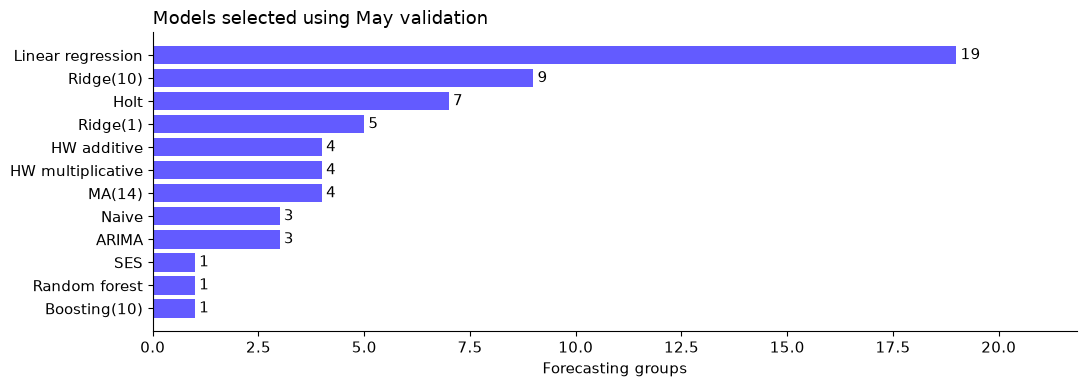

In [6]:

# One shared calendar and a frozen selection rule for every group.
test = scores[scores.split.eq('test')].copy()
validation = scores[scores.split.eq('validation')].copy()
choices = selection[selection.scope.eq('all')].set_index('group_id')
assert len(choices) == 61 and choices.n.eq(28).all()
baseline = test[test.model.eq('Seasonal naive')].set_index('group_id')
selected = choices[['model']].reset_index().merge(test, on=['group_id','model'], validate='one_to_one').set_index('group_id')
selected = selected.join(representatives[['inventory_type','material_name','unit']])
# A compact, light-theme diagram shares the timeline's palette and typography.
fig, ax = plt.subplots(figsize=(14,3.1),facecolor='white')
ax.set_xlim(-.45,4.45); ax.set_ylim(0,1); ax.axis('off')
fig.suptitle('From model comparison to next week’s requirements',x=.035,y=.97,ha='left',fontsize=19,fontweight='bold',color='#202938')
steps = [('MAY','Compare models','28 validation days'),('MAY','Choose per group','Freeze the model choice'),('JUNE','Evaluate forecasts','Compare with the baseline'),('JUNE 30','Update the fit','Use all available history'),('JULY 1–7','Forecast requirements','Daily quantities for planning')]
for i,(period,title,detail) in enumerate(steps):
    color = '#7864ce' if i<2 else '#368ac1'
    if i<4:
        ax.annotate('',xy=(i+.83,.69),xytext=(i+.17,.69),arrowprops={'arrowstyle':'->','color':'#c4c9d2','lw':1.6})
    ax.scatter(i,.69,s=700,color=color,zorder=3)
    ax.text(i,.69,str(i+1),ha='center',va='center',fontsize=13,color='white',weight='bold')
    ax.text(i,.92,period,ha='center',fontsize=10,color='#596579')
    ax.text(i,.40,title,ha='center',fontsize=12,weight='bold',color='#202938')
    ax.text(i,.21,detail,ha='center',fontsize=10,color='#596579')
fig.subplots_adjust(left=.025,right=.975,top=.78,bottom=.04)
plt.show()
member_names = groups.groupby('group_id').material_name.agg(' / '.join)
eligible = validation[validation.n.eq(28)].groupby('group_id').size()
minimum = validation[validation.n.eq(28)].groupby('group_id').MSE.min()
registry = choices[['model','MSE']].join(representatives[['unit']])
registry['Group / stock items'] = member_names
registry['Eligible candidates'] = eligible
registry = registry.rename(columns={'model':'Selected model','MSE':'May MSE','unit':'Unit'})
registry = registry[['Group / stock items','Unit','Selected model','May MSE','Eligible candidates']]
registry = order_groups(registry)
expandable(registry.reset_index(drop=True), 'Show the remaining model selections')
registry.to_csv(OUT / 'group_selection.csv', index_label='group_id')
note('Eligible candidates counts the model configurations that produced every required May forecast; different parameter settings count separately. The table covers all 61 groups. Cup/lid pairs appear together because their BOM requirements are proportional. Every selected model has the lowest eligible May MSE for its group. Compare MSE within a group, not across different units.')
counts = choices.groupby('model').size().sort_values()
fig, ax = plt.subplots(figsize=(11,4))
ax.barh(counts.index, counts.values, color=PURPLE)
ax.bar_label(ax.containers[0], padding=3)
ax.set_xlim(0, counts.max()*1.15); ax.set_xlabel('Forecasting groups'); ax.set_title('Models selected using May validation')
plt.tight_layout(); plt.show()
top_model = counts.idxmax()
note(f'{top_model} is selected for {int(counts.max())} of {len(registry)} groups. Each selection has the lowest May MSE among eligible candidates. June evaluates whether those choices remain effective.')




## 7. Evaluate May-selected models on June data

Models were selected using May MSE. This table reports their June performance; June results do not change the selection. We compare the selected forecasts with recorded requirements on June 1–28. The baseline repeats the seven observed days immediately before each weekly forecast origin. Mean MASE gives each group equal weight, allowing us to compare items measured in different units.

In [7]:

common = selected.index.intersection(baseline.index)
assert len(common) == 61 and selected.n.eq(28).all()
assert np.isfinite(selected.MASE).all() and np.isfinite(baseline.MASE).all()
comparison = pd.DataFrame([
    {'Forecast':'Previous-week baseline','Groups':len(common),'Mean MASE':baseline.loc[common,'MASE'].mean()},
    {'Forecast':'May-selected models','Groups':len(common),'Mean MASE':selected.loc[common,'MASE'].mean()},
])
improvement = 100*(1-comparison.iloc[1]['Mean MASE']/comparison.iloc[0]['Mean MASE'])
wins = int((selected.loc[common,'MASE'] < baseline.loc[common,'MASE']).sum())
note(f'The selected models have {improvement:.1f}% lower mean MASE than the baseline and lower MASE in {wins} of 61 groups. Selection used May; these are later June results, not another model-selection round.')
review = selected[['MAE','RMSE','Bias','MASE']].rename(columns=lambda c: 'June '+c)
review['Group / stock items'] = member_names
review['Unit'] = selected.unit
review['Model selected in May'] = selected.model
review['Baseline MASE'] = baseline.MASE
review = review[['Group / stock items','Unit','Model selected in May','June MAE','June RMSE','June Bias','June MASE','Baseline MASE']]
review = order_groups(review)
expandable(review.reset_index(drop=True), 'Show the remaining June results')
review.to_csv(OUT / 'group_test_results.csv', index_label='group_id')
note('MAE and RMSE use the displayed unit. Positive Bias means underforecasting. MASE uses historical seven-day differences as its scale; compare it with the June baseline column rather than assuming that any value below 1 beats that baseline.')
# Family-only comparisons are supplementary, not the selection used for July.
strategy_rows = []
for scope, label in [('statistical','Classical only'),('ml','ML only'),('all','Classical + ML')]:
    chosen = selection[selection.scope.eq(scope)][['group_id','model']]
    result = chosen.merge(test,on=['group_id','model'],validate='one_to_one')
    assert len(result)==61 and result.n.eq(28).all()
    strategy_rows.append({'Candidate pool':label,'Groups':len(result),'June mean MASE':result.MASE.mean()})
strategies = pd.DataFrame(strategy_rows)
strategies.to_csv(OUT / 'strategy_comparison.csv',index=False)


Group / stock items,Unit,Model selected in May,June MAE,June RMSE,June Bias,June MASE,Baseline MASE
Brazilian - Organic,each,Boosting(10),1.300,1.737,0.329,0.997,1.439
Our Old Time Diner Blend,each,Linear regression,1.027,1.257,-0.101,1.050,1.349
Espresso Roast,each,Linear regression,1.007,1.181,-0.030,1.010,1.495
Primo Espresso Roast,each,Linear regression,0.806,1.086,0.210,0.910,1.366
Columbian Medium Roast,each,Linear regression,1.138,1.293,-0.604,1.134,1.492
Ethiopia,each,Ridge(10),1.183,1.475,-0.113,1.030,1.519
Jamacian Coffee River,each,Ridge(1),1.050,1.169,-0.443,1.062,1.513
Civet Cat,each,Ridge(10),2.271,4.493,0.274,1.234,1.807
Group / stock items,Unit,Model selected in May,June MAE,June RMSE,June Bias,June MASE,Baseline MASE
Organic Decaf Blend,each,Ridge(10),1.151,1.574,0.188,0.949,1.468


## 8. Compare errors across stock types

We bring all groups together within Ingredients, Packaging and Finished goods. The left panels compare average June error; the right panels show how that error changes each day. Errors are scaled before averaging, so different units are not added together.

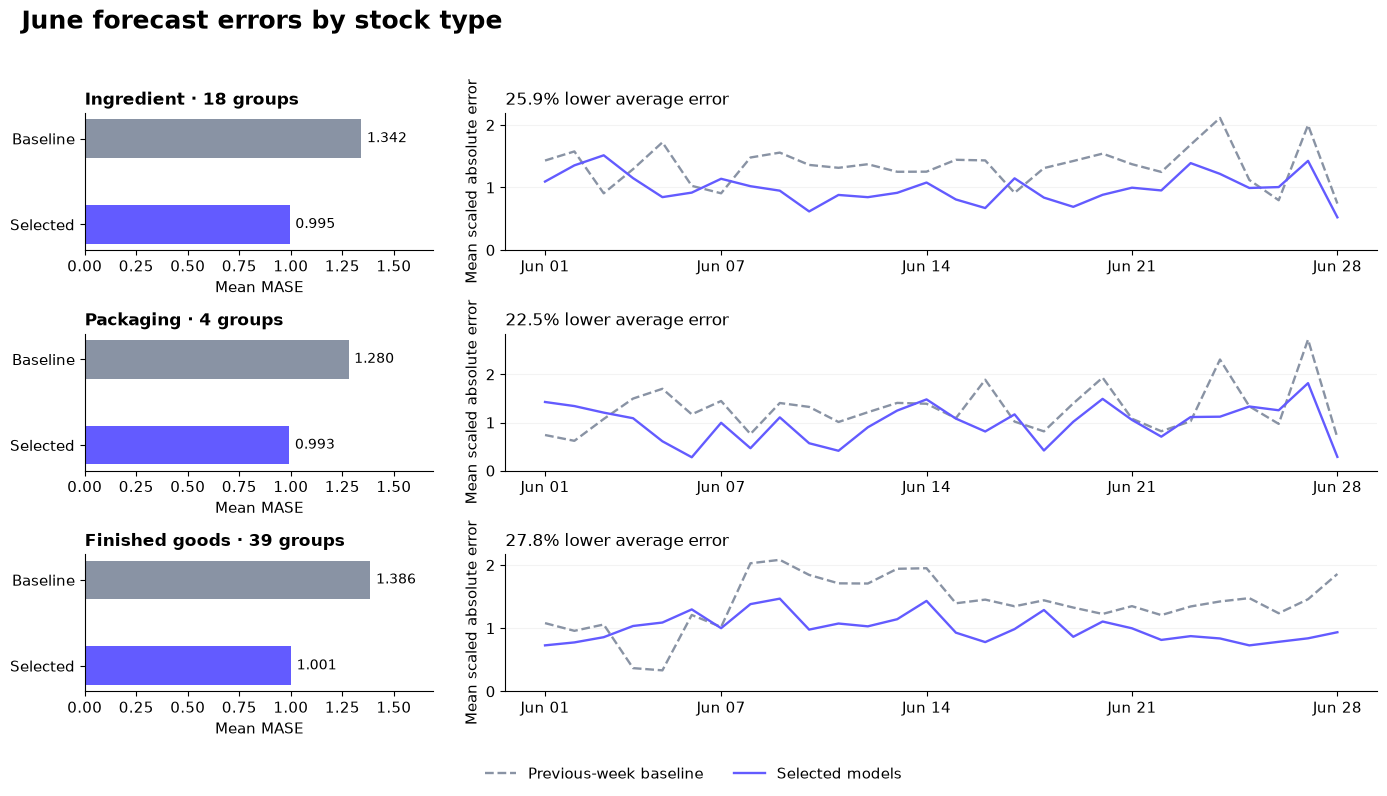

In [8]:

chosen_rows = forecasts[forecasts.split.eq('test')].merge(choices[['model']].reset_index(),on=['group_id','model'],validate='many_to_one')
base_rows = forecasts[forecasts.split.eq('test') & forecasts.model.eq('Seasonal naive')].copy()
def daily_scaled_errors(frame):
    frame = frame.join(representatives.inventory_type,on='group_id')
    frame['scaled_error'] = (frame.actual-frame.forecast).abs()/frame.scale
    assert np.isfinite(frame.scaled_error).all()
    return frame.groupby(['inventory_type','date']).scaled_error.mean()
chosen_daily = daily_scaled_errors(chosen_rows)
base_daily = daily_scaled_errors(base_rows)
stock_types = ['Ingredient','Packaging','Finished goods']
fig, axes = plt.subplots(3,2,figsize=(14,8),gridspec_kw={'width_ratios':[1,2.5]})
for row,kind in enumerate(stock_types):
    chosen = chosen_daily.loc[kind]
    base = base_daily.loc[kind]
    left,right = axes[row]
    left.barh(['Baseline','Selected'],[base.mean(),chosen.mean()],color=[GRAY,PURPLE],height=.45)
    left.bar_label(left.containers[0],fmt='%.3f',padding=4,fontsize=10)
    left.set_xlim(0,max(base_daily.groupby(level=0).mean())*1.22)
    left.invert_yaxis(); left.set_xlabel('Mean MASE')
    count = int(representatives.inventory_type.eq(kind).sum())
    gain = 100*(1-chosen.mean()/base.mean())
    left.set_title(f'{kind} · {count} groups',fontsize=12,weight='bold')
    right.plot(base.index,base.values,color=GRAY,ls='--',label='Previous-week baseline',lw=1.7)
    right.plot(chosen.index,chosen.values,color=PURPLE,label='Selected models',lw=1.7)
    right.set_title(f'{gain:.1f}% lower average error',fontsize=12)
    right.set_ylabel('Mean scaled absolute error'); right.set_ylim(bottom=0)
    right.set_xticks(pd.to_datetime(['2023-06-01','2023-06-07','2023-06-14','2023-06-21','2023-06-28']))
    right.xaxis.set_major_formatter(md.DateFormatter('%b %d'))
    right.grid(axis='y',alpha=.15)
handles,labels = axes[0,1].get_legend_handles_labels()
fig.legend(handles,labels,loc='lower center',ncol=2,frameon=False)
fig.suptitle('June forecast errors by stock type',x=.02,ha='left',fontsize=18,weight='bold')
fig.tight_layout(rect=(0,.05,1,.95)); plt.show()
ingredient_base = base_daily.loc['Ingredient'].mean()
ingredient_selected = chosen_daily.loc['Ingredient'].mean()
packaging_gain = 100*(1-chosen_daily.loc['Packaging'].mean()/base_daily.loc['Packaging'].mean())
finished_gain = 100*(1-chosen_daily.loc['Finished goods'].mean()/base_daily.loc['Finished goods'].mean())
note(f'For ingredients, mean MASE falls from {ingredient_base:.3f} with the previous-week baseline to {ingredient_selected:.3f} with the selected models. This is a {100*(1-ingredient_selected/ingredient_base):.1f}% reduction in average scaled error: (baseline − selected) ÷ baseline. These scores measure error, not percentages of demand; lower is better.')
note(f'Average scaled error also falls by {packaging_gain:.1f}% for packaging and {finished_gain:.1f}% for finished goods. Across all three stock types, the selected models forecast June requirements more accurately on average than simply repeating the previous week. The daily lines show that the advantage is not the same every day.')


## 9. Forecast next week’s requirements

Selecting a model identifies the method, not the quantities to stock. We refit each selected method using records through June 30, then forecast July 1–7. The 61 groups expand back to 64 stock items for planning.

In [9]:

july = pd.read_csv(OUT / 'item_july_forecasts.csv', parse_dates=['date'])
assert len(july)==64*7 and july.material_id.nunique()==64
weekly = july.groupby(['material_id','material_name','unit','selected_model','deployed_model']).forecast.sum().reset_index()
weekly['_product_order'] = weekly.material_id.map(product_order)
weekly = weekly.sort_values(['_product_order','material_id']).drop(columns='_product_order')
# Item-level line charts: June history and seven July forecasts, in native units.
from io import StringIO
panels = []
options = []
for row in weekly.sort_values('material_name', key=lambda names: names.str.casefold()).itertuples(index=False):
    item_id, name, unit = row.material_id, row.material_name, row.unit
    kind = groups.set_index('material_id').loc[item_id, 'inventory_type']
    past = daily.loc['2023-06-01':'2023-06-30', item_id]
    ahead = july.loc[july.material_id.eq(item_id)].sort_values('date')
    fig, ax = plt.subplots(figsize=(13,4.2), facecolor='white')
    ax.plot(past.index,past,color=GRAY,alpha=.4,lw=1.8,label='June recorded requirements')
    ax.plot([past.index[-1],ahead.date.iloc[0]],[past.iloc[-1],ahead.forecast.iloc[0]],color=PURPLE,alpha=.4,ls=':')
    ax.axvspan(ahead.date.iloc[0],ahead.date.iloc[-1],color=PURPLE,alpha=.06)
    ax.plot(ahead.date,ahead.forecast,color=PURPLE,lw=2.4,marker='o',ms=4,label='July 1–7 forecast')
    ax.set_title(name,fontsize=15,weight='bold')
    ax.set_ylabel(f'Daily requirement ({unit})')
    ax.set_ylim(bottom=0)
    ax.grid(axis='y',alpha=.12)
    ax.set_xticks(pd.to_datetime(['2023-06-01','2023-06-07','2023-06-14','2023-06-21','2023-06-28','2023-07-01','2023-07-07']))
    ax.xaxis.set_major_formatter(md.DateFormatter('%b %d'))
    ax.legend(loc='upper center',bbox_to_anchor=(.5,-.17),ncol=2,frameon=False)
    fig.tight_layout()
    buffer = StringIO()
    fig.savefig(buffer,format='svg',bbox_inches='tight')
    plt.close(fig)
    svg = buffer.getvalue()[buffer.getvalue().index('<svg'):]
    hidden = '' if item_id == 'milk' else ' hidden'
    panels.append(f'<div class="item-forecast-panel" data-item="{escape(item_id)}"{hidden}><p class="forecast-total">July 1–7 total: <strong>{ahead.forecast.sum():,.2f} {escape(unit)}</strong></p>{svg}</div>')
    selected_attr = ' selected' if item_id == 'milk' else ''
    options.append(f'<option value="{escape(item_id)}" data-kind="{escape(kind)}"{selected_attr}>{escape(name)} ({escape(row.selected_model)})</option>')
controls = '<div class="forecast-controls"><label>Stock type<select class="forecast-type"><option selected>Ingredient</option><option>Packaging</option><option>Finished goods</option></select></label><label>Stock item<select class="forecast-item">'+''.join(options)+'</select></label></div>'
display(HTML('<div class="item-forecast-explorer">'+controls+''.join(panels)+'</div>'))
note('Choose a stock item to see its daily requirements. June provides context; purple shows the July forecast. The weekly total uses the item’s own unit.')
weekly.to_csv(OUT / 'weekly_requirements.csv',index=False)
july['day'] = july.date.dt.strftime('%b %d')
day_columns = sorted(july.day.unique())
requirements = july.pivot(index='material_id',columns='day',values='forecast')
requirements = weekly.merge(requirements,on='material_id',validate='one_to_one')
assert np.allclose(requirements[day_columns].sum(axis=1),requirements.forecast)
requirements = requirements[['material_name','unit',*day_columns,'forecast']].rename(columns={'material_name':'Stock item','unit':'Unit','forecast':'Week total'})
expandable(requirements, 'Show the remaining stock items', css_class='forecast-quantities')
fallbacks = weekly[weekly.selected_model.ne(weekly.deployed_model)]
if len(fallbacks):
    note(f'{len(fallbacks)} stock items use a fallback because the selected model could not be refitted. Both model names are shown below.')
    table(fallbacks[['material_name','selected_model','deployed_model']])
note('July actuals are not available, so these quantities cannot yet be scored. They are forecast requirements, not purchase orders: inventory planning also considers usable stock, incoming deliveries, lead times and shelf life. June remains the period used to evaluate forecast performance.')


Stock item,Unit,Jul 01,Jul 02,Jul 03,Jul 04,Jul 05,Jul 06,Jul 07,Week total
Brazilian - Organic,each,1.784,1.412,1.662,1.382,1.785,2.025,1.706,11.756
Our Old Time Diner Blend,each,0.476,1.216,0.516,0.694,0.688,1.138,1.730,6.458
Espresso Roast,each,0.771,0.997,1.224,1.333,1.460,1.854,2.259,9.897
Primo Espresso Roast,each,0.899,0.702,0.244,0.000,0.480,0.753,1.028,4.106
Columbian Medium Roast,each,1.174,0.236,1.085,1.270,1.434,1.884,1.871,8.953
Ethiopia,each,1.303,1.488,0.875,1.895,1.680,2.018,2.756,12.015
Jamacian Coffee River,each,1.041,1.132,1.023,1.216,1.286,1.813,1.393,8.903
Civet Cat,each,0.000,2.266,2.602,1.699,1.671,2.131,2.187,12.556
Stock item,Unit,Jul 01,Jul 02,Jul 03,Jul 04,Jul 05,Jul 06,Jul 07,Week total
Organic Decaf Blend,each,0.325,0.692,1.134,0.658,1.300,1.833,2.152,8.094
